# 01 · Datos: descarga, limpieza y exploración
**Responsable:** Persona A

Genera `data/processed/juegos.parquet`, que es la base de todos los demás notebooks.
La lógica de limpieza vive en `src/datos.py`; aquí solo se corre y se explora.

Decisiones (ver `src/config.py`):
- Se usa `games.csv` (el parquet de Hugging Face trae las etiquetas vacías). Su encabezado está corrido una columna y se corrige al leer.
- Solo juegos con **≥ 20 reseñas** (con menos, el % positivo es ruido).
- Objetivo: `bien_recibido = 1` si `pct_positivo > 0.80`.
- `Price` es el precio *con* el descuento del día de la foto → `precio_lista_usd = Price / (1 - Discount)`.
- Quetzales con tasa fija `TASA_GTQ_USD`; precio en oferta con `DESCUENTO_TIPICO` (plan B).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))  # para poder importar src/ desde notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src import config as C
from src.datos import cargar_juegos

df = cargar_juegos()
df.shape

(44568, 37)

In [2]:
df.head()

,appid,nombre,fecha,precio_actual_usd,descuento_actual,edad_requerida,dlc_count,logros,windows,mac,...,publicadores,precio_lista_usd,precio_lista_gtq,precio_oferta_gtq,es_gratis,anio,antiguedad_anios,total_resenas,pct_positivo,bien_recibido
0,496350,Supipara - Chapter 1 Spring Has Come!,2016-07-29,5.24,0.65,0,0,0,True,False,...,[MangaGamer],14.97,115.27,57.64,False,2016,10.277892,255,0.988235,1
1,1034400,Mystery Solitaire The Black Raven,2019-05-06,4.99,0.00,0,0,0,True,True,...,[8floor],4.99,38.42,19.21,False,2019,7.509925,24,0.875000,1
2,1934300,Armored Brigade II,2025-04-08,35.99,0.10,0,1,0,True,False,...,[Matrix Games],39.99,307.92,153.96,False,2025,1.585216,130,0.900000,1
3,1157670,Hepta Beats,2021-05-07,0.99,0.00,0,0,9,True,False,...,[Matheus Bigatão],0.99,7.62,3.81,False,2021,5.505818,32,0.875000,1
4,1540330,MUMBA IV: Egypt Jewels,2021-12-13,0.59,0.00,0,1,100,True,True,...,[Airem],0.59,4.54,2.27,False,2021,4.903491,25,0.760000,0


## Variable objetivo

bien_recibido
1    0.527509
0    0.472491
Name: proportion, dtype: float64


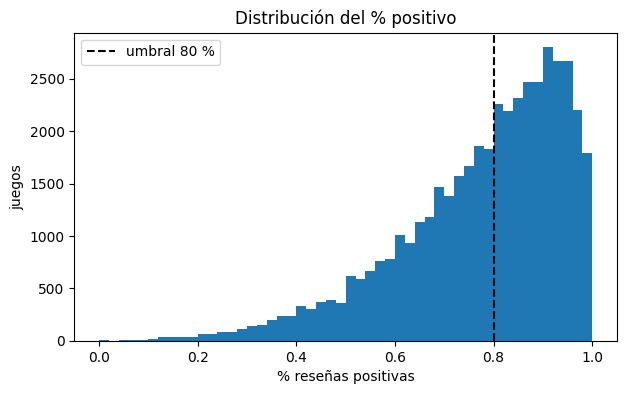

In [3]:
print(df["bien_recibido"].value_counts(normalize=True))

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(df["pct_positivo"], bins=50)
ax.axvline(C.UMBRAL_BIEN_RECIBIDO, color="k", ls="--", label="umbral 80 %")
ax.set(xlabel="% reseñas positivas", ylabel="juegos", title="Distribución del % positivo")
ax.legend()
fig.savefig(C.FIGURAS / "01_pct_positivo.png", dpi=120, bbox_inches="tight")

## Precio y descuento

Gratis: 13.4%
count    38603.000000
mean        82.905479
std        130.019661
min          3.770000
25%         23.020000
50%         53.820000
75%        115.190000
max      15399.230000
Name: precio_lista_gtq, dtype: float64
Con descuento el día de la foto: 49.9%


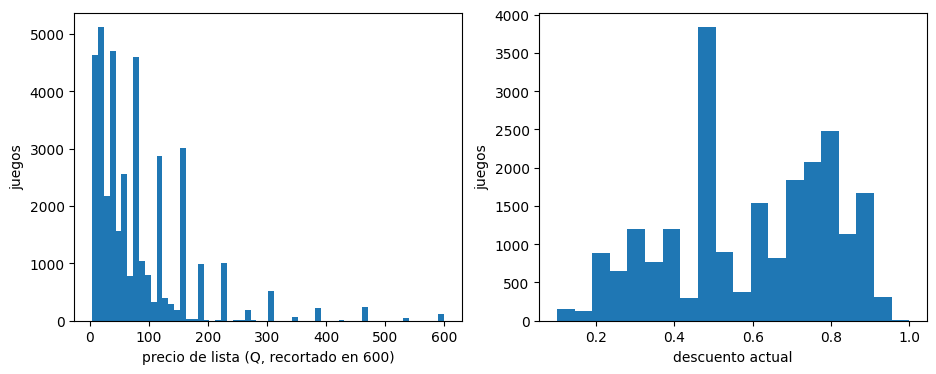

In [4]:
pagos = df[~df["es_gratis"]]
print(f"Gratis: {df['es_gratis'].mean():.1%}")
print(pagos["precio_lista_gtq"].describe())
print(f"Con descuento el día de la foto: {(df['descuento_actual'] > 0).mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(pagos["precio_lista_gtq"].clip(upper=600), bins=60)
axes[0].set(xlabel="precio de lista (Q, recortado en 600)", ylabel="juegos")
axes[1].hist(df.loc[df["descuento_actual"] > 0, "descuento_actual"], bins=20)
axes[1].set(xlabel="descuento actual", ylabel="juegos")
fig.savefig(C.FIGURAS / "01_precio_descuento.png", dpi=120, bbox_inches="tight")

## Etiquetas, géneros y antigüedad

In [5]:
etiquetas = df["etiquetas"].explode()
print("Etiquetas únicas:", etiquetas.nunique())
print("Juegos sin etiquetas:", (df["etiquetas"].map(len) == 0).sum())
etiquetas.value_counts().head(20)

Etiquetas únicas: 451
Juegos sin etiquetas: 1


etiquetas
Singleplayer      26497
Indie             26167
Adventure         20152
Action            19624
Casual            17808
2D                13282
Simulation        10960
Strategy          10125
Atmospheric       10120
RPG                9642
Story Rich         8966
Puzzle             8726
3D                 7931
Exploration        7524
Multiplayer        7130
Pixel Graphics     7091
Cute               7072
First-Person       7053
Colorful           6694
Fantasy            6103
Name: count, dtype: int64

In [6]:
tasa = (df[["etiquetas", "bien_recibido"]].explode("etiquetas")
          .groupby("etiquetas")["bien_recibido"].agg(["mean", "size"])
          .query("size >= 500").sort_values("mean"))
pd.concat([tasa.head(8), tasa.tail(8)])

,mean,size
etiquetas,,
Massively Multiplayer,0.214286,1204
Zombies,0.392144,1553
Automobile Sim,0.397380,687
Survival,0.398415,3785
Realistic,0.401767,3395
Third-Person Shooter,0.409136,1007
Sports,0.416468,2101
Grand Strategy,0.418212,593
Romance,0.737176,1735


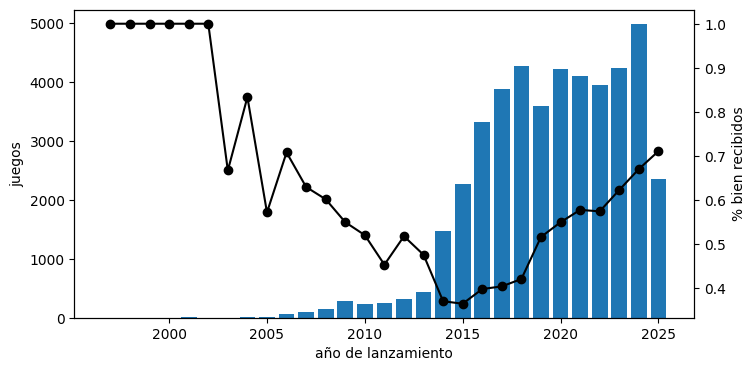

In [7]:
por_anio = df.groupby("anio").agg(juegos=("appid", "size"), pct_bien=("bien_recibido", "mean"))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(por_anio.index, por_anio["juegos"])
ax2 = ax.twinx(); ax2.plot(por_anio.index, por_anio["pct_bien"], color="k", marker="o")
ax.set(xlabel="año de lanzamiento", ylabel="juegos"); ax2.set_ylabel("% bien recibidos")
fig.savefig(C.FIGURAS / "01_por_anio.png", dpi=120, bbox_inches="tight")

## Notas para el equipo
- Las columnas de listas (`etiquetas`, `generos`, ...) vuelven del parquet como `numpy.ndarray`; usar `list(x)` si hace falta.
- **No usar como predictores** las columnas de `C.COLUMNAS_PROHIBIDAS` (fuga de datos).